# Regresi durasi pengiriman
 ## Tujuan demo
 Jalankan sel dari atas ke bawah. Penjelasan, tabel, dan grafik memakai keluaran run baru di `.cache/demo-notebook/regresi/`.
 Kode eksperimen utama berada di `regresi.py` dan dipanggil langsung oleh notebook ini.

 Sebelum demo, gunakan Python 3.12 dan pasang dependensi dari root repo dengan
 `python -m pip install -r kode/requirements-notebook.txt`.
 Simpan data rilis dosen di `data_uts_ml/`. Notebook ini dapat dibuka melalui JupyterLab atau VS Code.
 Untuk Colab, unggah salinan repo lengkap dan data terlebih dahulu, lalu buka notebook ini dari folder repo.

## 1. Persiapan lingkungan

In [1]:
TASK = 'regresi'
INPUTS = ['regresi_train.csv.gz', 'regresi_test.csv.gz']
from pathlib import Path
import importlib.util
import json
import os
import subprocess
import sys
import time

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

current = Path.cwd().resolve()
ROOT = current if (current / "kode").is_dir() else current.parent
assert (ROOT / "kode" / (TASK + ".py")).is_file(), "Buka notebook dari root repo atau folder kode/."
DATA = Path(os.environ.get("UTS_DATA_DIR", ROOT / "data_uts_ml"))
OUTPUT = ROOT / ".cache" / "demo-notebook" / TASK
OUTPUT.mkdir(parents=True, exist_ok=True)

spec = importlib.util.spec_from_file_location("eksperimen_" + TASK, ROOT / "kode" / (TASK + ".py"))
experiment = importlib.util.module_from_spec(spec)
spec.loader.exec_module(experiment)
plt.rcParams.update({"figure.figsize": (8, 4), "font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.axisbelow": True})

## 2. Data dan pertanyaan
Satu baris data merepresentasikan satu paket. Tampilkan lima contoh untuk membaca kolom yang dipakai.

In [2]:
sample = pd.read_csv(DATA / INPUTS[0], nrows=5)
display(sample[['id_paket', 'layanan', 'jarak_km', 'berat_kg', 'durasi_jam']])

,id_paket,layanan,jarak_km,berat_kg,durasi_jam
0,P24198861,ekspres,1077.6,0.44,40.4
1,P44313480,reguler,829.3,0.71,78.7
2,P18332724,kargo,758.6,NaN,101.3
3,P85422083,ekspres,396.2,1.11,60.3
4,P60211760,kargo,254.6,NaN,63.1


## 3. Metode dan asumsi
 P50 memperkirakan median waktu pengiriman. P90 adalah batas atas satu sisi untuk sekitar 90% durasi.
 Kami membandingkan baseline kuantil, Ridge log, dan LightGBM kuantil pada fold maju Mei-Juni.
 Fitur jumlah scan dikeluarkan karena ketersediaannya saat pickup belum terjamin.
 Kalibrasi memakai cohort terpisah sebelum Agustus. Penilaian Agustus bersifat retrospektif.

## 4. Jalankan ulang eksperimen
Sel ini melakukan audit, tuning, kalibrasi, dan ekspor dari awal. Tunggu sampai selesai.

In [3]:
missing = [name for name in INPUTS if not (DATA / name).is_file()]
assert not missing, "Masukkan data dosen ke data_uts_ml/. Berkas belum ada: " + ", ".join(missing)
start = time.perf_counter()
subprocess.run(
    [sys.executable, str(ROOT / "kode" / (TASK + ".py")), "--data", str(DATA), "--output", str(OUTPUT)],
    check=True,
)
print(f"Eksperimen selesai dalam {time.perf_counter() - start:.1f} detik.")
metrics = json.loads((OUTPUT / "hasil" / TASK / "metrics.json").read_text(encoding="utf-8"))

Eksperimen selesai dalam 211.7 detik.


## 5. Angka Agustus yang dijelaskan dalam laporan

In [4]:
rows = []
for name, key in [("Baseline", "baseline"), ("LightGBM awal", "raw"), ("Setelah kalibrasi", "calibrated")]:
    result = metrics["august"][key]
    rows.append({"Model": name, "Pinball P50 (jam)": result["pinball_p50"],
                 "Pinball P90 (jam)": result["pinball_p90"], "Cakupan P90 (%)": 100 * result["coverage_p90"]})
display(pd.DataFrame(rows).round(3))

,Model,Pinball P50 (jam),Pinball P90 (jam),Cakupan P90 (%)
0,Baseline,17.156,15.969,89.411
1,LightGBM awal,10.829,11.416,88.240
2,Setelah kalibrasi,10.829,11.405,91.153


## 6. Mengapa kalibrasi dibutuhkan?

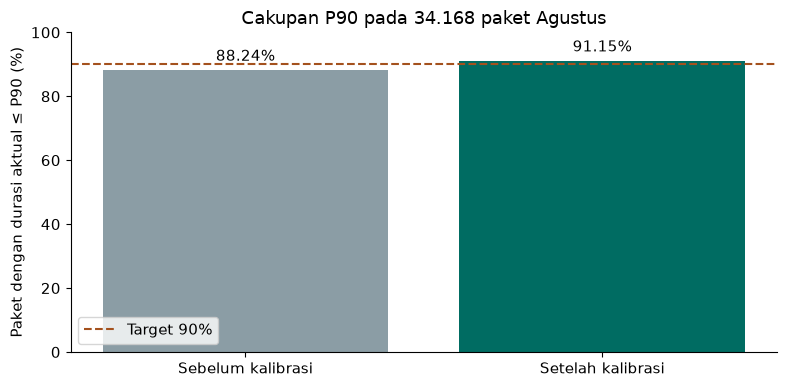

In [5]:
fig, ax = plt.subplots()
coverage = [metrics["august"][key]["coverage_p90"] * 100 for key in ("raw", "calibrated")]
bars = ax.bar(["Sebelum kalibrasi", "Setelah kalibrasi"], coverage, color=["#8B9DA5", "#006C62"])
ax.axhline(90, color="#A4511D", linestyle="--", label="Target 90%")
ax.bar_label(bars, labels=[f"{value:.2f}%" for value in coverage], padding=4)
ax.set(ylim=(0, 100), ylabel="Paket dengan durasi aktual ≤ P90 (%)", title="Cakupan P90 pada 34.168 paket Agustus")
ax.legend()
plt.tight_layout()
plt.show()

Cakupan yang diperoleh berlaku pada cohort Agustus. Jaminan pada bulan uji bergantung pada perubahan distribusi dan label pengiriman yang tersedia.

## 7. Periksa keluaran resmi

In [6]:
predictions = pd.read_csv(OUTPUT / "prediksi_regresi.csv")
assert predictions["id_paket"].is_unique and predictions["p90"].ge(predictions["p50"]).all()
print(f"{len(predictions):,} paket. Semua P90 ≥ P50.")
display(predictions.head())

60,000 paket. Semua P90 ≥ P50.


,id_paket,p50,p90
0,P83639399,58.842925,75.507683
1,P26553951,105.883598,136.373280
2,P32537117,58.278286,86.532542
3,P28750760,61.000774,70.200747
4,P96580009,50.713305,63.447390


## Latihan menjawab
 Sebutkan tujuan eksperimen, satu keputusan metode, angka yang baru dihitung, dan batas kesimpulannya.
 Buka `../laporan.pdf` untuk pembahasan semua subsoal dan `../hasil/` untuk bukti tersimpan.